# 03 Churn prediction
Goal: rank customers by risk of placing no order in the 60 days after the cutoff (`churned_next_60d = 1`).

In [2]:
import sys; sys.path.insert(0, '..')
import warnings; warnings.filterwarnings('ignore')
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy.stats import loguniform
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, average_precision_score, confusion_matrix,
                             precision_recall_curve, roc_auc_score, roc_curve)
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from src.cleaning import clean_customers, clean_orders, build_customer_features

SEED = 42
customers, _ = clean_customers(pd.read_csv('C:\\Users\\lakshraj computer\\Downloads\\QuickCart_Assessment_Keval_Chauhan\\quickcart_data\\customers.csv'))
orders, _ = clean_orders(pd.read_csv('C:\\Users\\lakshraj computer\\Downloads\\QuickCart_Assessment_Keval_Chauhan\\quickcart_data\\orders.csv'))
CUTOFF = orders['order_ts'].max().normalize() + pd.Timedelta(days=1)
df = build_customer_features(customers, orders, CUTOFF).merge(pd.read_csv('C:\\Users\\lakshraj computer\\Downloads\\QuickCart_Assessment_Keval_Chauhan\\quickcart_data\\churn_labels.csv'), on='customer_id')
y = df['churned_next_60d']
print(df.shape, '| cutoff:', CUTOFF.date())

(4000, 19) | cutoff: 2026-06-30


## 1. Leakage check
Every candidate column is scored on its own with a single-feature ROC-AUC (0.5 = no signal, 1.0 = perfect). A single column that separates churners almost perfectly is a leak.

In [3]:
cols = [c for c in df.columns if c not in ['customer_id', 'last_order', 'signup_date', 'churned_next_60d']]

def univariate_auc(s):
    if not pd.api.types.is_numeric_dtype(s):
        s = s.map(y.groupby(s).mean())
    a = roc_auc_score(y, s.fillna(s.median()))
    return max(a, 1 - a)

pd.Series({c: univariate_auc(df[c]) for c in cols}).sort_values(ascending=False).round(3)

account_status         0.930
total_spend            0.727
frequency              0.722
recency_days           0.600
acquisition_channel    0.580
pct_cancelled          0.566
tenure_days            0.559
plan_type              0.557
avg_spend              0.548
pct_rain               0.535
city                   0.522
avg_delivery_min       0.518
age                    0.508
gender                 0.505
discount_share         0.500
dtype: float64

In [4]:
df.groupby('account_status')['churned_next_60d'].agg(churn_rate='mean', customers='size').round(3)

,churn_rate,customers
account_status,,
active,0.010,3496
closed,1.000,88
dormant,0.548,416


**Leak: `account_status` — excluded.** Its single-column AUC is far above every legitimate feature, and the table shows why: all 88 `closed` accounts churned (100%), 55% of `dormant` accounts churned, and only 1% of `active` ones did. The status was recorded after the cutoff, so it describes the outcome rather than predicting it.

`customer_id`, `signup_date` and `last_order` are also excluded (identifier and raw dates; `tenure_days` and `recency_days` carry the information). All other features were built only from orders before the cutoff.

## 2. Imbalance

In [5]:
print(f'Churn rate: {y.mean():.1%} ({y.sum()} of {len(y)} customers)')
print(f'Accuracy of predicting "nobody churns": {1 - y.mean():.1%}')

Churn rate: 8.8% (352 of 4000 customers)
Accuracy of predicting "nobody churns": 91.2%


**Accuracy is the wrong headline metric.** A model that predicts "nobody churns" is right 91.2% of the time yet finds none of the 352 churners and saves no money. Metrics that focus on the churner class (PR-AUC, recall and precision at a threshold, profit) are the honest ones.

## 3. Models
Same stratified 80/20 split and same preprocessing for all four. Class imbalance is handled with class weights.

In [6]:
NUM = ['recency_days', 'frequency', 'total_spend', 'avg_spend', 'discount_share', 'tenure_days',
       'pct_rain', 'avg_delivery_min', 'pct_cancelled', 'age']
CAT = ['city', 'gender', 'plan_type', 'acquisition_channel']
X = df[NUM + CAT]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)

pre = ColumnTransformer([
    ('num', Pipeline([('imp', SimpleImputer(strategy='median', add_indicator=True)), ('sc', StandardScaler())]), NUM),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), CAT)])
make = lambda model: Pipeline([('pre', pre), ('model', model)])

spw = (y_tr == 0).sum() / (y_tr == 1).sum()
models = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=SEED),
    'Random Forest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, class_weight='balanced_subsample',
                                            random_state=SEED, n_jobs=-1),
    'XGBoost': XGBClassifier(scale_pos_weight=spw, eval_metric='logloss', random_state=SEED),
    'LightGBM': LGBMClassifier(scale_pos_weight=spw, random_state=SEED, verbose=-1)}
fitted = {name: make(m).fit(X_tr, y_tr) for name, m in models.items()}
probs = {name: m.predict_proba(X_te)[:, 1] for name, m in fitted.items()}

## 4. Evaluation
Precision, recall and the confusion matrix use each model's profit-maximising threshold (₹150 offer cost, ₹1,200 per saved churner; see section 6).

In [7]:
COST, VALUE = 150, 1200
THRESHOLDS = np.linspace(0.01, 0.99, 99)
yt = y_te.to_numpy()

def profit(p, t):
    contact = p >= t
    return VALUE * (contact & (yt == 1)).sum() - COST * contact.sum()

def best_threshold(p):
    return THRESHOLDS[np.argmax([profit(p, t) for t in THRESHOLDS])]

def evaluate(name, p):
    t = best_threshold(p)
    tn, fp, fn, tp = confusion_matrix(yt, p >= t).ravel()
    return {'model': name, 'ROC-AUC': roc_auc_score(yt, p), 'PR-AUC': average_precision_score(yt, p),
            'threshold': t, 'precision': tp / (tp + fp), 'recall': tp / (tp + fn),
            'profit (Rs)': profit(p, t), 'TP': tp, 'FP': fp, 'FN': fn, 'TN': tn}

table = pd.DataFrame([evaluate(n, p) for n, p in probs.items()]).set_index('model')
table.round(3)

,ROC-AUC,PR-AUC,threshold,precision,recall,profit (Rs),TP,FP,FN,TN
model,,,,,,,,,,
Logistic Regression,0.786,0.394,0.54,0.228,0.643,24450,45,152,25,578
Random Forest,0.756,0.378,0.29,0.237,0.529,21000,37,119,33,611
XGBoost,0.647,0.298,0.29,0.333,0.300,15750,21,42,49,688
LightGBM,0.678,0.330,0.41,0.371,0.371,20700,26,44,44,686


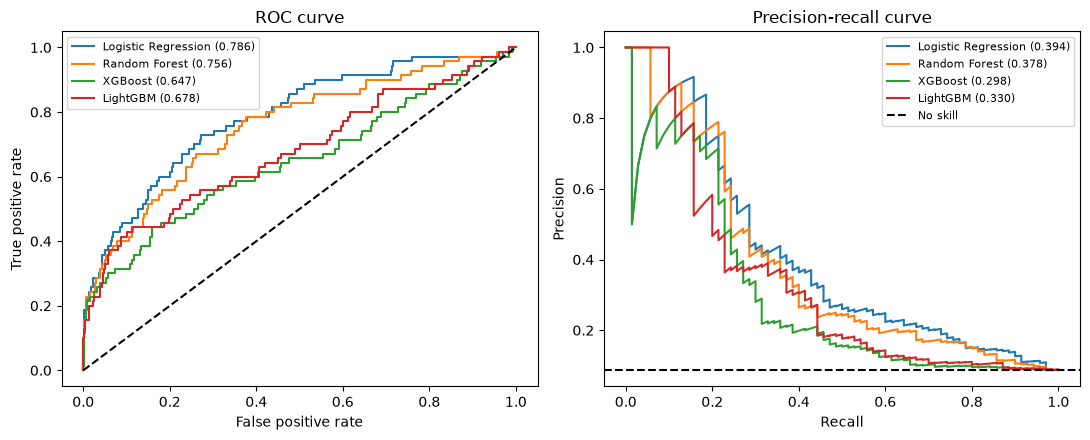

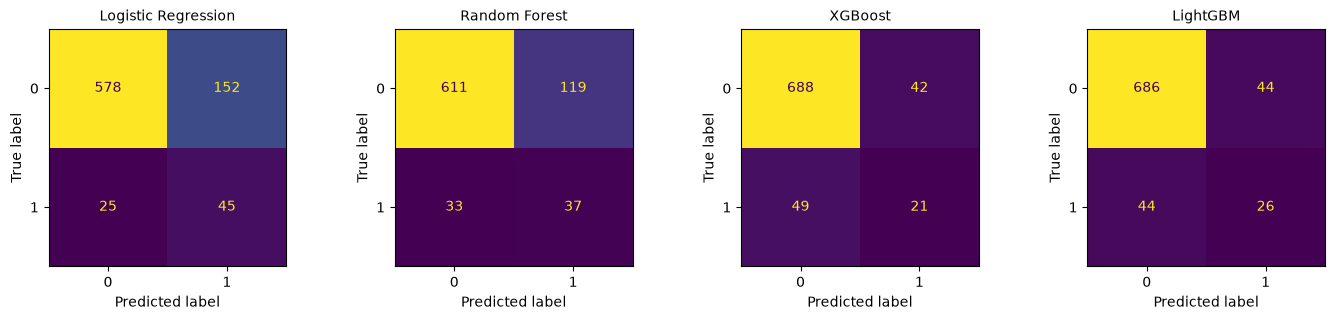

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(yt, p); axes[0].plot(fpr, tpr, label=f"{name} ({table.loc[name, 'ROC-AUC']:.3f})")
    pr, rc, _ = precision_recall_curve(yt, p); axes[1].plot(rc, pr, label=f"{name} ({table.loc[name, 'PR-AUC']:.3f})")
axes[0].plot([0, 1], [0, 1], 'k--'); axes[0].set(title='ROC curve', xlabel='False positive rate', ylabel='True positive rate')
axes[1].axhline(yt.mean(), color='k', ls='--', label='No skill'); axes[1].set(title='Precision-recall curve', xlabel='Recall', ylabel='Precision')
for ax in axes: ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 4, figsize=(14, 3.2))
for ax, (name, p) in zip(axes, probs.items()):
    ConfusionMatrixDisplay.from_predictions(yt, p >= table.loc[name, 'threshold'], ax=ax, colorbar=False)
    ax.set_title(name, fontsize=10)
plt.tight_layout(); plt.show()

**Result:** Logistic Regression is best on both ROC-AUC (0.786) and PR-AUC (0.394), ahead of Random Forest (0.756 / 0.376), LightGBM (0.678 / 0.330) and XGBoost (0.647 / 0.298). The boosted models overfit on only 3,200 training rows, and churn here is driven by a few smooth effects that a linear model captures well. The test set holds just 70 churners, so small gaps between models are partly noise.

## 5. Tuning
Logistic Regression is the best model on both ROC-AUC and PR-AUC, so it is the one tuned: 25 random trials, 5-fold stratified CV on the training set, scored by PR-AUC.

In [9]:
search = RandomizedSearchCV(
    make(LogisticRegression(solver='liblinear', max_iter=5000, random_state=SEED)),
    {'model__C': loguniform(1e-3, 1e2), 'model__penalty': ['l1', 'l2'], 'model__class_weight': [None, 'balanced']},
    n_iter=25, scoring='average_precision', cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
    random_state=SEED, n_jobs=-1).fit(X_tr, y_tr)
tuned = search.best_estimator_
probs['Logistic Regression (tuned)'] = tuned.predict_proba(X_te)[:, 1]
print(search.best_params_, '| CV PR-AUC:', round(search.best_score_, 3))
gain = pd.DataFrame([evaluate(n, probs[n]) for n in ['Logistic Regression', 'Logistic Regression (tuned)']]).set_index('model')
gain[['ROC-AUC', 'PR-AUC', 'threshold', 'precision', 'recall', 'profit (Rs)']].round(3)

{'model__C': np.float64(0.5414413211338525), 'model__class_weight': 'balanced', 'model__penalty': 'l1'} | CV PR-AUC: 0.351


,ROC-AUC,PR-AUC,threshold,precision,recall,profit (Rs)
model,,,,,,
Logistic Regression,0.786,0.394,0.54,0.228,0.643,24450
Logistic Regression (tuned),0.787,0.389,0.52,0.215,0.714,25050


**Answer:** Tuning is **not worth the complexity**. Test ROC-AUC moves from 0.786 to 0.787 and PR-AUC drops from 0.394 to 0.389. The profit-maximising threshold shifts and profit rises by Rs 600 (24,450 to 25,050), which is within the noise of a 70-churner test set. I keep the simpler default Logistic Regression as the final model.

## 6. Threshold and profit
Profit = ₹1,200 x churners contacted - ₹150 x customers contacted (assumes the offer saves every contacted churner, as the brief states).

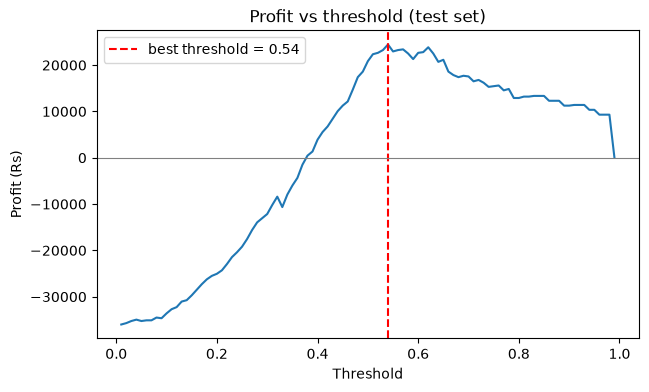

Best threshold 0.54: profit Rs 24,450, contacting 197 of 800 customers
Contact everyone: Rs -36,000 | contact no one: Rs 0


In [10]:
final = 'Logistic Regression'
p = probs[final]
profits = np.array([profit(p, t) for t in THRESHOLDS])
t_best = THRESHOLDS[profits.argmax()]

plt.figure(figsize=(7, 4))
plt.plot(THRESHOLDS, profits); plt.axvline(t_best, color='red', ls='--', label=f'best threshold = {t_best:.2f}')
plt.axhline(0, color='grey', lw=0.8)
plt.title('Profit vs threshold (test set)'); plt.xlabel('Threshold'); plt.ylabel('Profit (Rs)'); plt.legend(); plt.show()

contacted = int((p >= t_best).sum())
print(f'Best threshold {t_best:.2f}: profit Rs {profits.max():,.0f}, contacting {contacted} of {len(p)} customers')
print(f'Contact everyone: Rs {profit(p, 0):,.0f} | contact no one: Rs 0')

**Answer:** The profit-maximising threshold is **0.54**, giving **Rs 24,450** profit on the test set by contacting 197 of 800 customers. Precision is 22.8% and recall is 64.3% (45 of the 70 churners reached). Contacting everyone would lose Rs 36,000, because the offer only pays off when more than 12.5% of those contacted are real churners (150 / 1,200), and the base churn rate is 8.8%.

## 7. Explain
Permutation importance on the test set: how much ROC-AUC drops when one original column is shuffled.

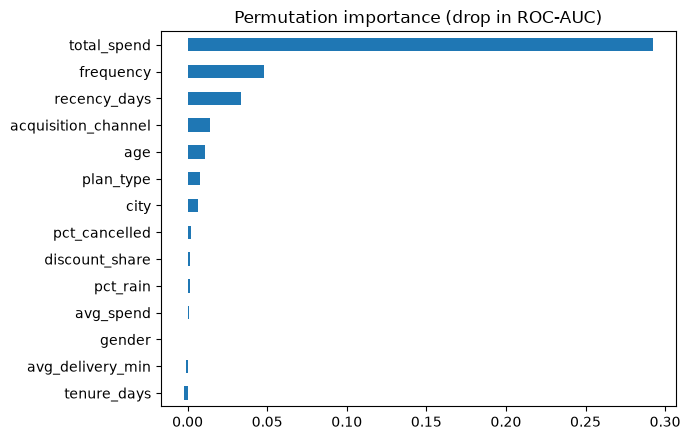

total_spend            0.292
frequency              0.048
recency_days           0.033
acquisition_channel    0.014
age                    0.011
plan_type              0.008
dtype: float64

In [11]:
imp = permutation_importance(fitted['Logistic Regression'], X_te, y_te, scoring='roc_auc', n_repeats=20, random_state=SEED)
imp = pd.Series(imp.importances_mean, index=X_te.columns).sort_values()
imp.plot.barh(figsize=(7, 4.5), title='Permutation importance (drop in ROC-AUC)'); plt.tight_layout(); plt.show()
imp.sort_values(ascending=False).round(3).head(6)

In [12]:
for c in ['total_spend', 'frequency', 'recency_days']:
    print(df.groupby(pd.qcut(df[c], 4, duplicates='drop'), observed=True)['churned_next_60d'].mean().round(3), '\n')

total_spend
(-0.001, 5553.065]        0.191
(5553.065, 12338.725]     0.077
(12338.725, 23688.652]    0.058
(23688.652, 157468.14]    0.026
Name: churned_next_60d, dtype: float64 

frequency
(-0.001, 9.0]    0.186
(9.0, 19.0]      0.069
(19.0, 36.0]     0.062
(36.0, 240.0]    0.028
Name: churned_next_60d, dtype: float64 

recency_days
(-0.001, 1.0]    0.068
(1.0, 5.0]       0.049
(5.0, 11.0]      0.071
(11.0, 332.0]    0.128
Name: churned_next_60d, dtype: float64 



**Top three churn drivers, in plain words:**
1. **Low total spend**: customers in the lowest-spend quartile churn at 19.1%, against 2.6% in the highest. By far the strongest signal.
2. **Few orders**: customers with 9 or fewer orders churn at 18.6%, against 2.8% for those with more than 36. Spend and order count move together, so they mostly tell the same story.
3. **Time since the last order**: customers who have not ordered for 11 or more days churn at 12.8%, against 5-7% for recent buyers.

Marketing takeaway: target light, low-spending customers who have gone quiet for about two weeks.

## Written question: monitoring the monthly retrain
- **Score drift:** compare the distribution of predicted churn probabilities and of key inputs (spend, frequency, recency) with the training data each month.
- **Real performance once labels arrive:** after each 60-day window closes, track PR-AUC, recall at the chosen threshold and the realised profit, and alert on a clear drop from the training-time values (PR-AUC 0.39, profit about Rs 24k on 800 customers).
- **Calibration:** check that predicted probabilities still match observed churn rates in each score band, since the threshold depends on them.
- **Business and data checks:** the churn rate itself, the share of customers contacted, the uplift of contacted versus held-out customers, and the data pipeline (missing or new categories, late-arriving orders).
- Keep a small random control group that is never contacted, so the true effect of the offer can still be measured.